# Analyse de l’évolution des prix des carburants en France

Six carburants, six couleurs constantes : Gazole, SP95, SP98, E10, E85 et GPLc.
Les graphiques utilisent toutes les archives locales disponibles et fonctionnent sans Internet.

**Méthode :** dernière déclaration exploitable par station/carburant/jour, puis moyenne quotidienne des stations déclarantes et moyenne mensuelle des moyennes quotidiennes. Si la dernière déclaration est invalide, aucune déclaration antérieure ne la remplace. Aucun prix reporté aux jours suivants. Les règles de qualité du projet s’appliquent, dont la quarantaine des prix hors de [0,20 ; 5] €/L.

Les moyennes portent sur un panel variable, ne sont pas pondérées par les ventes et ne sont pas corrigées de l’inflation. Elles ne démontrent pas les causes politiques ou économiques des variations.

In [1]:
from pathlib import Path
import sys, json, calendar
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/processing/quality_rules.py').exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from src.analytics.data import read_prices
from src.processing.quality_rules import POLICY_VERSION

HISTORICAL = ROOT / 'data/cleaned/historical'
FILES = sorted(HISTORICAL.glob('[0-9][0-9][0-9][0-9].parquet'))
assert FILES, 'Aucune archive locale disponible.'
COLORS = {'Gazole':'#0072B2', 'SP95':'#E69F00', 'SP98':'#D55E00', 'E10':'#009E73', 'E85':'#CC79A7', 'GPLc':'#7A6C00'}
STYLES = ['-', '--', '-.', ':', '-', '--']
plt.rcParams.update({'figure.dpi':120, 'axes.spines.top':False, 'axes.spines.right':False})
print(f'Archives : {FILES[0].stem}–{FILES[-1].stem} | Politique : {POLICY_VERSION}')

Archives : 2007–2026 | Politique : 2026-11-17.1


## 1. Construire les séries mensuelles

La lecture se fait une année et un carburant à la fois pour limiter la mémoire. Cette cellule peut prendre plusieurs minutes. Seules les petites tables agrégées restent en mémoire. Les mois sans observation restent vides ; les mois incomplets sont signalés.

In [2]:
parts = []
for file in FILES:
    year = int(file.stem)
    report = json.loads((ROOT / 'data/quality' / f'{year}.json').read_text(encoding='utf-8'))
    cutoff = min(pd.Timestamp(report['last_price_date']).normalize(), pd.Timestamp(f'{year}-12-31'))
    dates = pd.date_range(f'{year}-01-01', cutoff)
    for fuel in COLORS:
        events = read_prices(file, fuel)
        events['day'] = events['price_reported_at'].dt.normalize()
        last = events.sort_values('price_reported_at').drop_duplicates(['station_id', 'day'], keep='last')
        valid = last.loc[last['analysis_eligible']]
        daily = valid.groupby('day').agg(price=('price_eur_l','mean'), stations=('station_id','nunique')).reindex(dates)
        daily['stations'] = daily['stations'].fillna(0)
        monthly = daily.resample('MS').agg(price=('price','mean'), days=('price','count'), stations=('stations','mean'))
        monthly['observed_calendar_days'] = daily.resample('MS').size()
        monthly['partial'] = monthly['observed_calendar_days'] < monthly.index.days_in_month
        monthly['fuel'] = fuel
        parts.append(monthly.rename_axis('month').reset_index())
        del events, last, valid, daily
    print(f'{year} terminé', flush=True)
monthly = pd.concat(parts, ignore_index=True)
monthly['year'] = monthly['month'].dt.year
monthly['month_number'] = monthly['month'].dt.month
assert not monthly.duplicated(['month','fuel']).any()
assert monthly.loc[monthly['days'].eq(0), 'price'].isna().all()
display(monthly.tail(12))

ValueError: the 'filters' keyword is not supported when the pyarrow.dataset module is not available

## 2. Évolution de tous les carburants

Chaque courbe garde sa couleur. Une absence de données provoque une interruption de la courbe et ne vaut pas zéro.

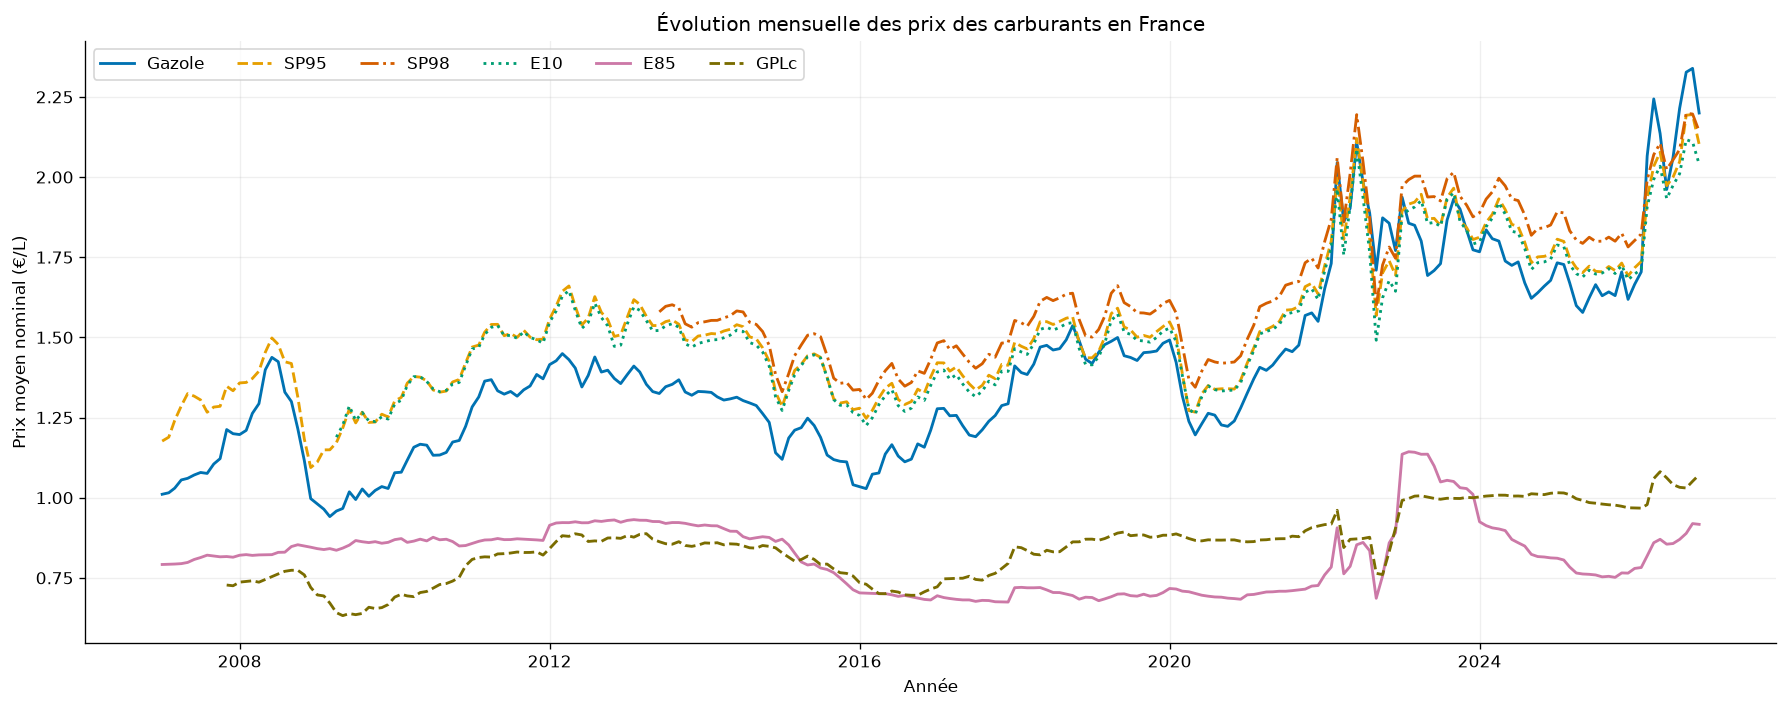

Mois partiels : 2026-11


In [ ]:
fig, ax = plt.subplots(figsize=(15, 6))
for (fuel, color), style in zip(COLORS.items(), STYLES):
    series = monthly.loc[monthly['fuel'].eq(fuel)].set_index('month')['price']
    series = series.reindex(pd.date_range(monthly['month'].min(), monthly['month'].max(), freq='MS'))
    ax.plot(series.index, series, label=fuel, color=color, linestyle=style, linewidth=1.7)
ax.set(title='Évolution mensuelle des prix des carburants en France', xlabel='Année', ylabel='Prix moyen nominal (€/L)')
ax.grid(alpha=.2)
ax.legend(ncol=6, loc='upper left')
fig.tight_layout()
plt.show()
partial = monthly.loc[monthly['partial'] & monthly['price'].notna(), 'month'].drop_duplicates()
if not partial.empty:
    print('Mois partiels :', ', '.join(partial.dt.strftime('%Y-%m')))

## Courbe globale : toutes les années et tous les carburants

Un point par mois, de la première à la dernière archive disponible. Chaque carburant disposant d’un prix mensuel reçoit le même poids. Cet indicateur n’est pas pondéré par les ventes et ne représente pas un prix réellement payé. La composition change lorsque certains carburants ne sont pas renseignés : le tableau indique leur nombre par mois. Les mois partiels restent signalés dans la section précédente.

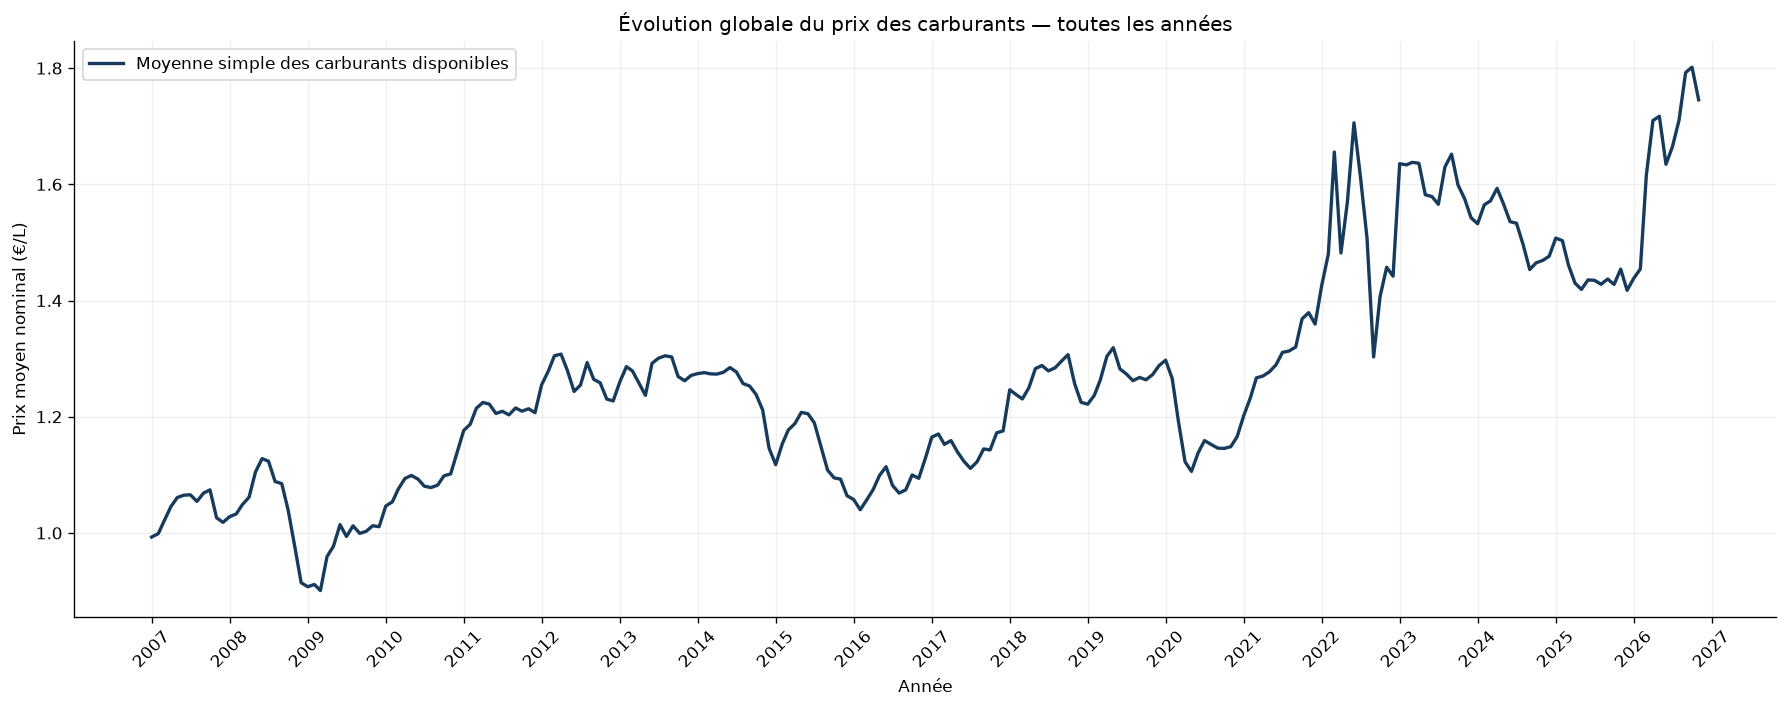

,prix_global,carburants_disponibles,mois_partiel
Mois,,,
2007-01-01,0.992961,3,False
2007-02-01,0.998826,3,False
2007-03-01,1.021187,3,False
2007-04-01,1.045299,3,False
2007-05-01,1.061004,3,False
...,...,...,...
2026-07-01,1.664431,6,False
2026-08-01,1.710093,6,False
2026-09-01,1.792448,6,False


Nombre de carburants représentés selon le mois : 3 à 6


In [ ]:
global_prices = monthly.groupby('month').agg(
    prix_global=('price', 'mean'),
    carburants_disponibles=('price', 'count'),
    mois_partiel=('partial', 'any'),
).reindex(pd.date_range(monthly['month'].min(), monthly['month'].max(), freq='MS'))
global_prices.index.name = 'Mois'
fig, ax = plt.subplots(figsize=(15, 6))
ax.plot(global_prices.index, global_prices['prix_global'], color='#163B5C', linewidth=2,
        label='Moyenne simple des carburants disponibles')
ax.set(title='Évolution globale du prix des carburants — toutes les années',
       xlabel='Année', ylabel='Prix moyen nominal (€/L)')
import matplotlib.dates as mdates
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
ax.tick_params(axis='x', rotation=45)
ax.grid(alpha=.2); ax.legend(); fig.tight_layout(); plt.show()
display(global_prices)
print('Nombre de carburants représentés selon le mois :',
      int(global_prices['carburants_disponibles'].min()), 'à',
      int(global_prices['carburants_disponibles'].max()))

## 3. Comparer les années mois par mois

Un panneau par année, les mêmes couleurs par carburant et la même échelle de prix. Modifier `YEARS_TO_COMPARE` pour sélectionner d’autres années. Les valeurs absentes et les mois futurs restent vides.

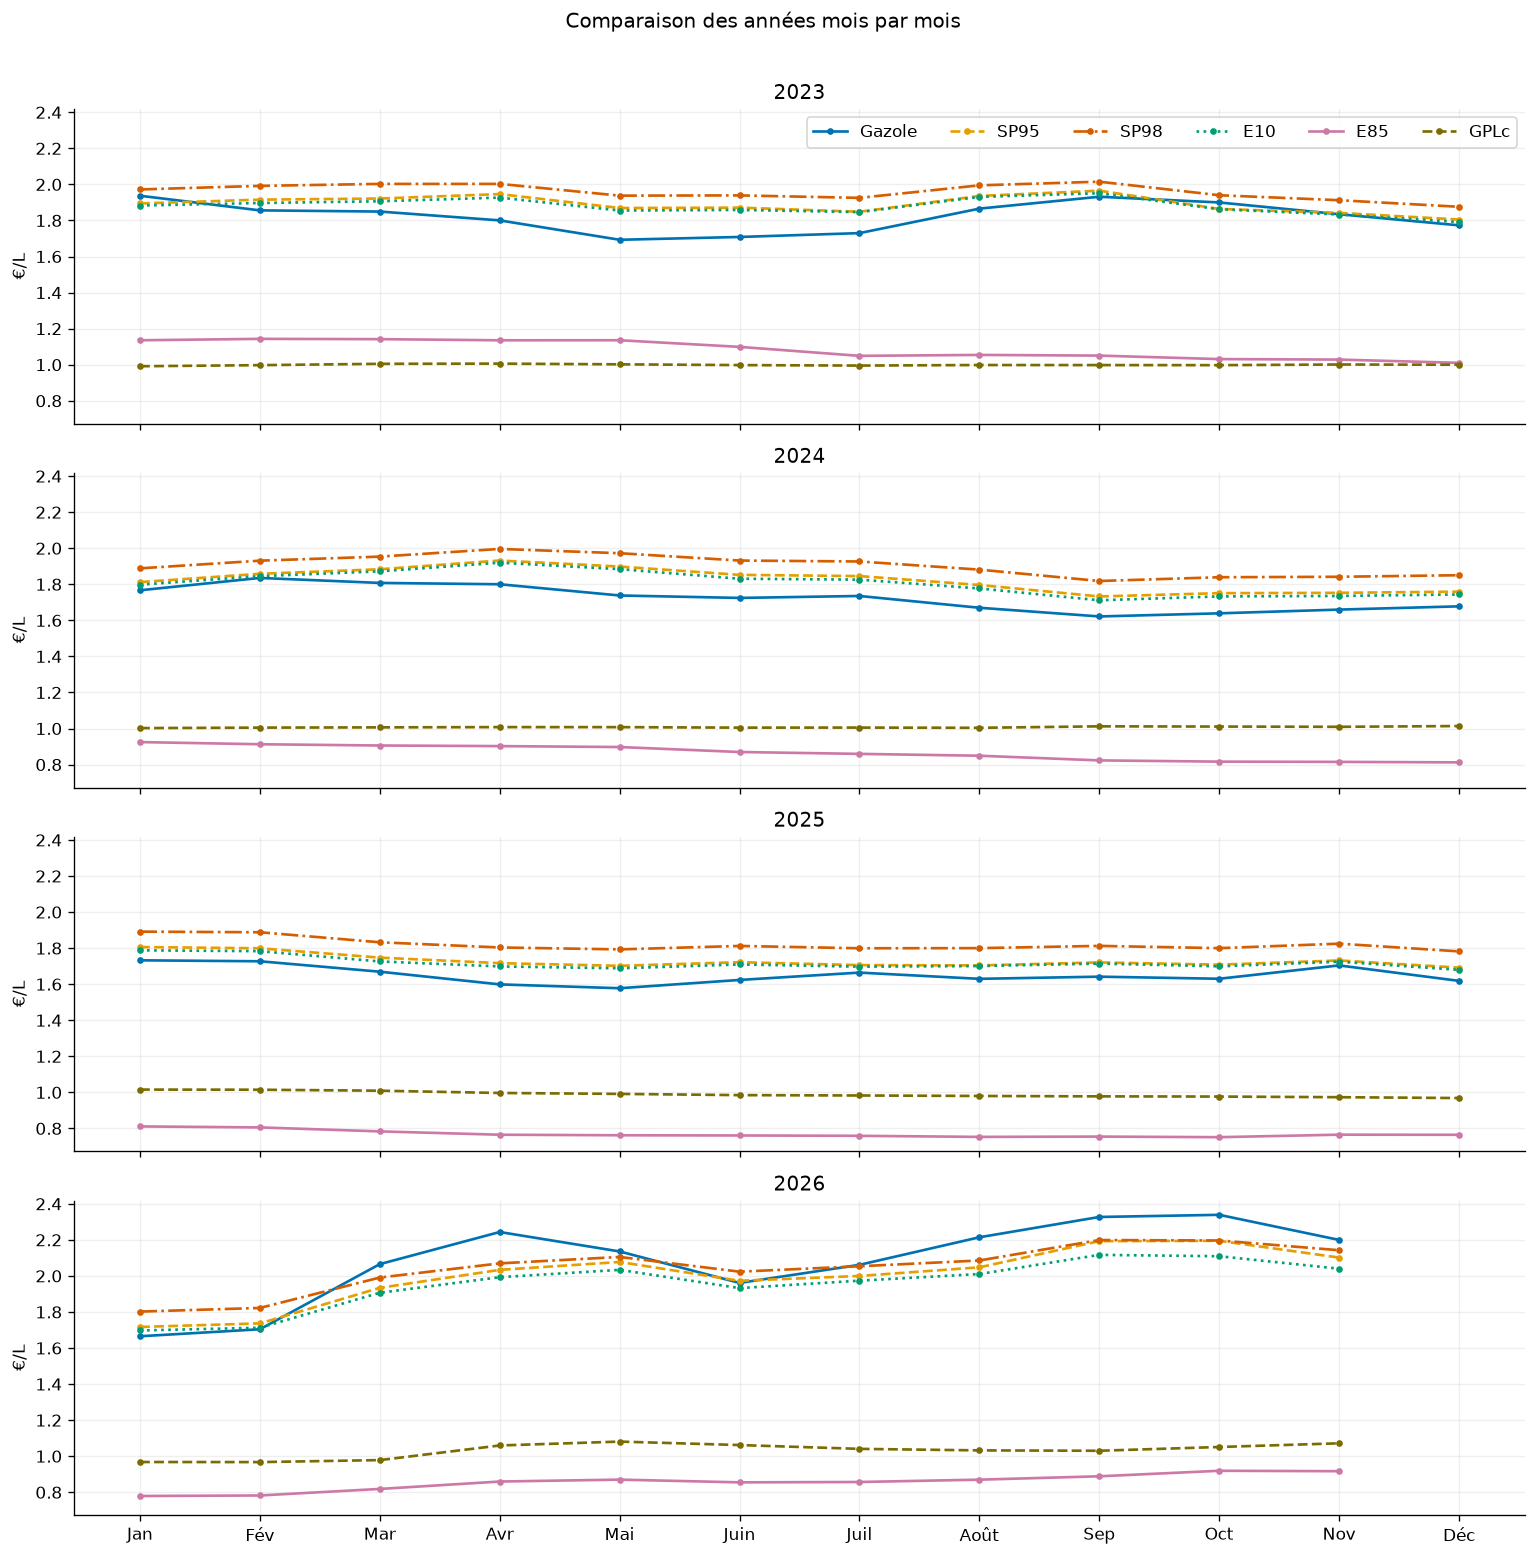

In [ ]:
YEARS_TO_COMPARE = sorted(monthly['year'].unique())[-4:]
fig, axes = plt.subplots(len(YEARS_TO_COMPARE), 1, figsize=(13, 3.2 * len(YEARS_TO_COMPARE)), sharex=True, sharey=True, squeeze=False)
for ax, year in zip(axes[:, 0], YEARS_TO_COMPARE):
    for (fuel, color), style in zip(COLORS.items(), STYLES):
        series = monthly.loc[monthly['year'].eq(year) & monthly['fuel'].eq(fuel)].set_index('month_number')['price'].reindex(range(1,13))
        ax.plot(series.index, series, label=fuel, color=color, linestyle=style, marker='.', linewidth=1.6)
    ax.set_title(str(year)); ax.set_ylabel('€/L'); ax.grid(alpha=.2)
axes[0,0].legend(ncol=6)
axes[-1,0].set_xticks(range(1,13), ['Jan','Fév','Mar','Avr','Mai','Juin','Juil','Août','Sep','Oct','Nov','Déc'])
fig.suptitle('Comparaison des années mois par mois', y=1.01)
fig.tight_layout()
plt.show()

## 4. Vérifier la couverture avant de conclure

Une évolution du nombre de stations déclarantes peut modifier la moyenne. Le nombre affiché est la moyenne quotidienne des stations déclarantes, jours sans déclaration inclus à zéro jusqu’à la dernière date de l’archive.

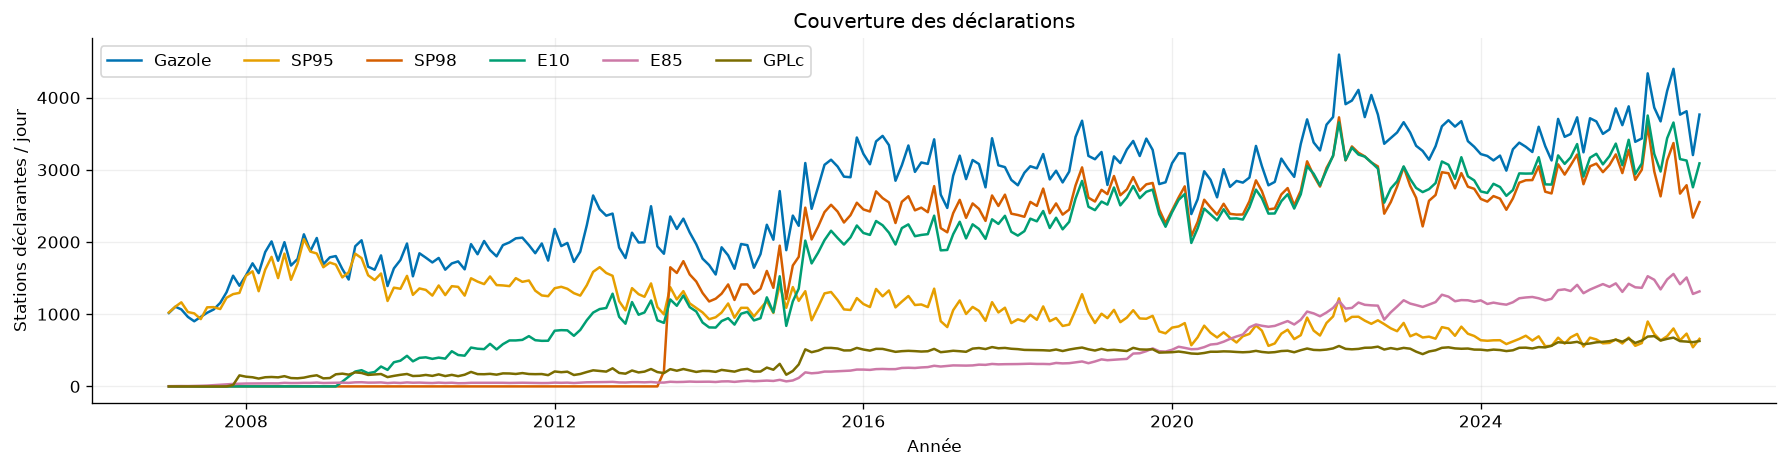

,premier_mois,dernier_mois,mois_avec_prix
fuel,,,
E10,2007-01-01,2026-11-01,212
E85,2007-01-01,2026-11-01,239
GPLc,2007-01-01,2026-11-01,229
Gazole,2007-01-01,2026-11-01,239
SP95,2007-01-01,2026-11-01,239
SP98,2007-01-01,2026-11-01,162


In [ ]:
fig, ax = plt.subplots(figsize=(15,4))
for fuel, color in COLORS.items():
    subset = monthly.loc[monthly['fuel'].eq(fuel)]
    ax.plot(subset['month'], subset['stations'], color=color, label=fuel)
ax.set(title='Couverture des déclarations', xlabel='Année', ylabel='Stations déclarantes / jour')
ax.legend(ncol=6); ax.grid(alpha=.2); fig.tight_layout(); plt.show()
display(monthly.groupby('fuel').agg(premier_mois=('month','min'), dernier_mois=('month','max'), mois_avec_prix=('price','count')))
# La table monthly est disponible pour poursuivre les analyses personnelles.

## 5. Mes observations

- Quels carburants évoluent ensemble ?
- Quelles différences observe-t-on entre les mêmes mois d’années différentes ?
- Les pics coïncident-ils avec un changement de couverture ?
- Quelles hypothèses nécessitent des données supplémentaires avant de parler de causalité ?

**Attention :** un premier mois présent dans la table n’est pas nécessairement le premier mois avec prix pour un carburant. Consulter les observations non manquantes.

## 6. Prix par région — tous les carburants et toutes les années

Une carte par carburant sur toute la période locale disponible. Le prix régional est la **moyenne des moyennes quotidiennes des stations déclarantes** sur les jours renseignés. Chaque jour renseigné a le même poids ; aucun prix n’est reconduit. Les règles de qualité précédentes s’appliquent.

Les coordonnées des stations sont rattachées aux contours régionaux locaux de 2026 : il s’agit donc d’un découpage géographique constant, même pour les années anciennes. Les points absents, ambigus ou hors contours sont exclus de ces cartes, sans être supprimés des données. Les contours sont simplifiés ; certaines stations côtières ou frontalières peuvent ne pas être rattachées. Les métadonnées annuelles ne garantissent pas la localisation à chaque date de déclaration.

Les six cartes partagent la même échelle. Les cinq régions ultramarines sont présentées en encarts, à des échelles géographiques différentes. Gris = absence de prix exploitable, jamais zéro. La moyenne sur toute la période masque les évolutions temporelles et les différences de couverture entre carburants : consulter aussi les dates et effectifs du tableau.

Fond : contours administratifs 2026, data.gouv.fr ; IGN / contributeurs OpenStreetMap, licence ODbL. Attribution complète : `assets/maps/SOURCE.md`. Aucune connexion nécessaire.

In [ ]:
import numpy as np
from matplotlib.path import Path as PolygonPath
from matplotlib.patches import Polygon
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from src.analytics.data import read_stations

geometry = json.loads((ROOT / 'assets/maps/regions_france.geojson').read_text(encoding='utf-8'))
regions = [f for f in geometry['features'] if len(f['properties']['code']) == 2]
region_names = {f['properties']['code']:f['properties']['nom'] for f in regions}

def polygons(feature):
    g = feature['geometry']
    return [g['coordinates']] if g['type'] == 'Polygon' else g['coordinates']

def attach_regions(stations):
    points = stations[['longitude','latitude']].to_numpy(dtype=float, na_value=np.nan)
    matches = np.zeros(len(stations), dtype=int)
    codes = np.full(len(stations), None, dtype=object)
    for region in regions:
        inside = np.zeros(len(stations), dtype=bool)
        for rings in polygons(region):
            exterior = np.asarray(rings[0])
            candidates = (np.isfinite(points).all(axis=1) &
                (points[:,0] >= exterior[:,0].min()) & (points[:,0] <= exterior[:,0].max()) &
                (points[:,1] >= exterior[:,1].min()) & (points[:,1] <= exterior[:,1].max()))
            idx = np.flatnonzero(candidates)
            hit = PolygonPath(exterior).contains_points(points[idx])
            for hole in rings[1:]:
                hit &= ~PolygonPath(hole).contains_points(points[idx])
            inside[idx] |= hit
        matches += inside
        codes[inside] = region['properties']['code']
    codes[matches != 1] = None
    return pd.DataFrame({'station_id':stations['station_id'].to_numpy(), 'region':codes})

regional_parts, mapping_audit = [], []
for file in FILES:
    stations = read_stations(file)
    mapping = attach_regions(stations)
    mapping_audit.append({'annee':int(file.stem), 'stations':len(mapping),
                          'sans_region':int(mapping['region'].isna().sum())})
    for fuel in COLORS:
        events = read_prices(file, fuel)
        events['day'] = events['price_reported_at'].dt.normalize()
        last = events.sort_values('price_reported_at').drop_duplicates(['station_id','day'], keep='last')
        valid = last.loc[last['analysis_eligible'], ['station_id','day','price_eur_l']]
        valid = valid.merge(mapping.dropna(subset=['region']), on='station_id', validate='many_to_one')
        daily_region = valid.groupby(['region','day']).agg(price=('price_eur_l','mean'), stations=('station_id','nunique')).reset_index()
        summary = daily_region.groupby('region').agg(total_daily_price=('price','sum'), days=('price','count'),
            station_days=('stations','sum'), first_date=('day','min'), last_date=('day','max')).reset_index()
        summary['fuel'] = fuel
        regional_parts.append(summary)
        del events, last, valid, daily_region
    print(f'Carte : {file.stem} terminé', flush=True)
region_prices = pd.concat(regional_parts, ignore_index=True).groupby(['region','fuel']).agg(
    total_daily_price=('total_daily_price','sum'), days=('days','sum'), station_days=('station_days','sum'),
    first_date=('first_date','min'), last_date=('last_date','max')).reset_index()
region_prices['price'] = region_prices['total_daily_price'] / region_prices['days']
region_prices['stations_per_day'] = region_prices['station_days'] / region_prices['days']
region_prices['region_name'] = region_prices['region'].map(region_names)
assert not region_prices.duplicated(['region','fuel']).any()
assert region_prices['price'].between(.2,5).all()
display(pd.DataFrame(mapping_audit))

Carte : 2007 terminé


Carte : 2008 terminé


Carte : 2009 terminé


Carte : 2010 terminé


Carte : 2011 terminé


Carte : 2012 terminé


... (11 outputs left out)

Carte : 2024 terminé


Carte : 2025 terminé


Carte : 2026 terminé


,annee,stations,sans_region
0,2007,7904,286
1,2008,8394,90
2,2009,9387,118
3,2010,10130,180
4,2011,10001,194
5,2012,10256,174
6,2013,10807,203
7,2014,11064,250
8,2015,12333,244
9,2016,12391,247


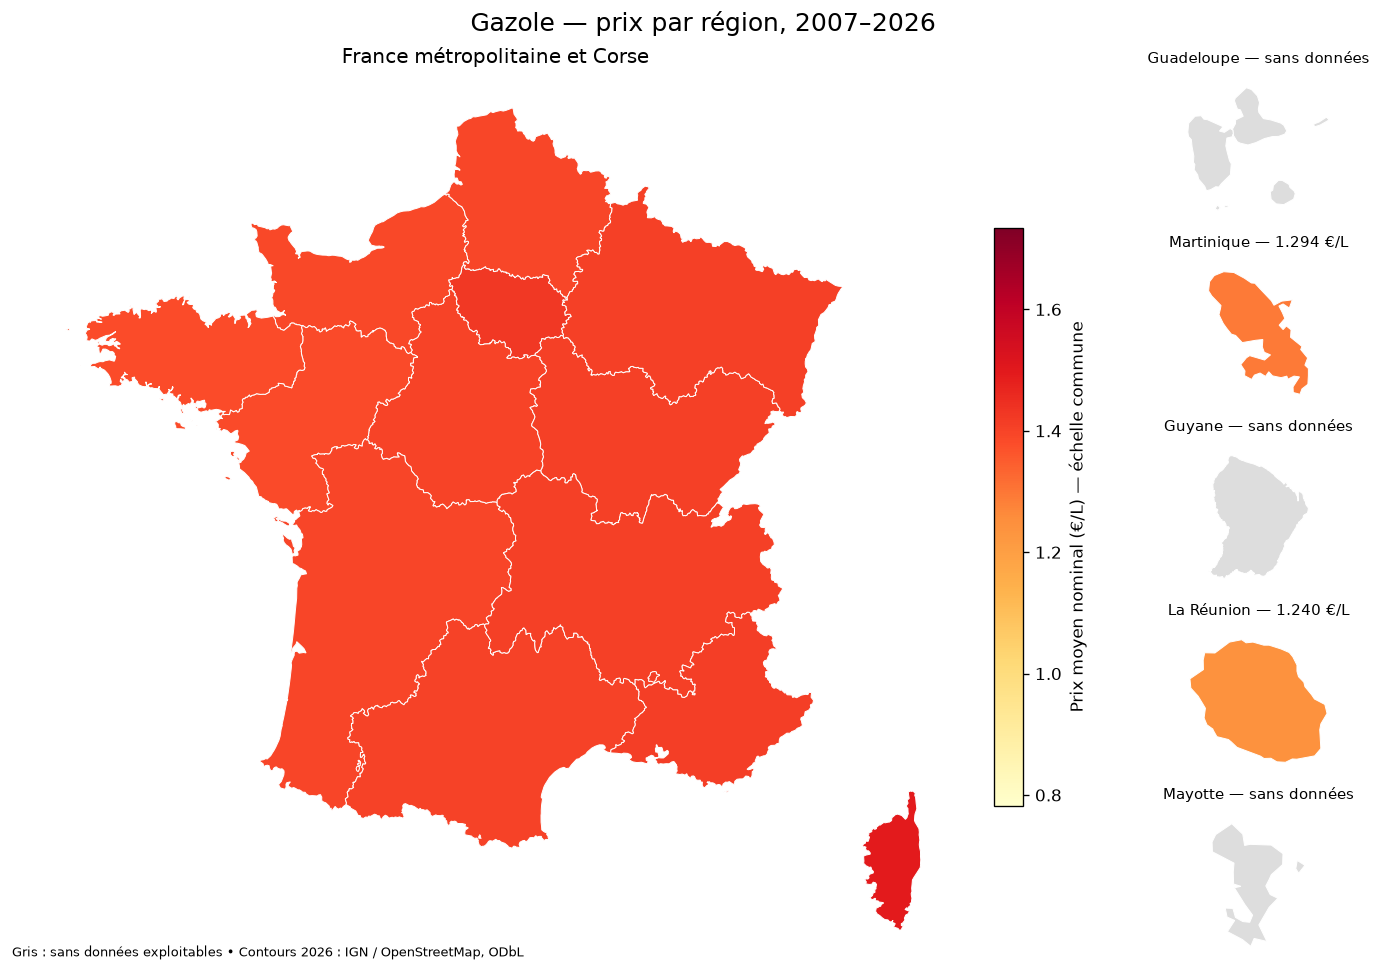

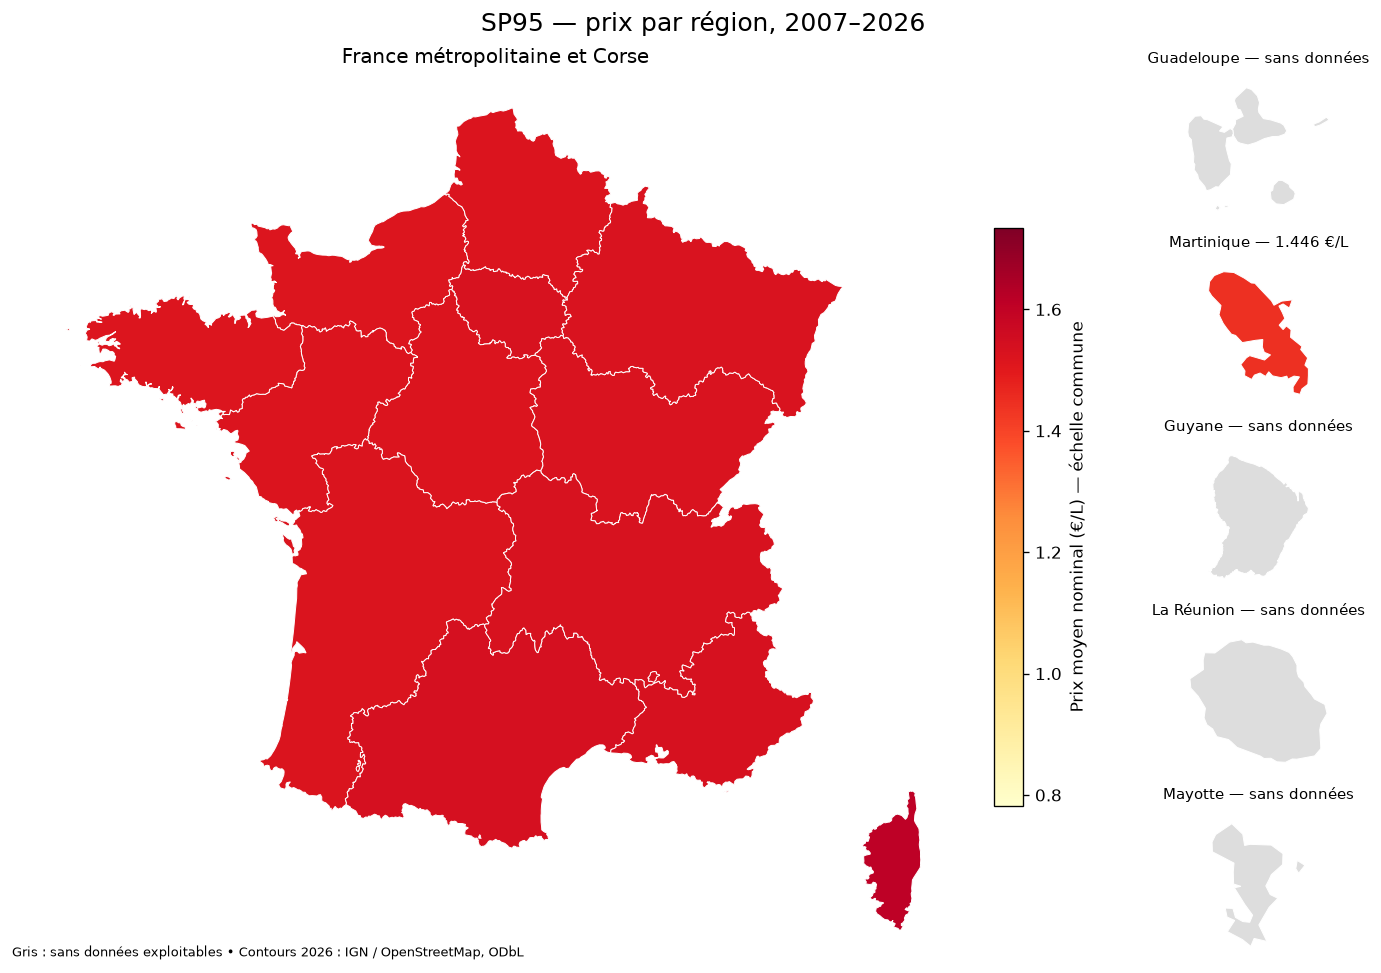

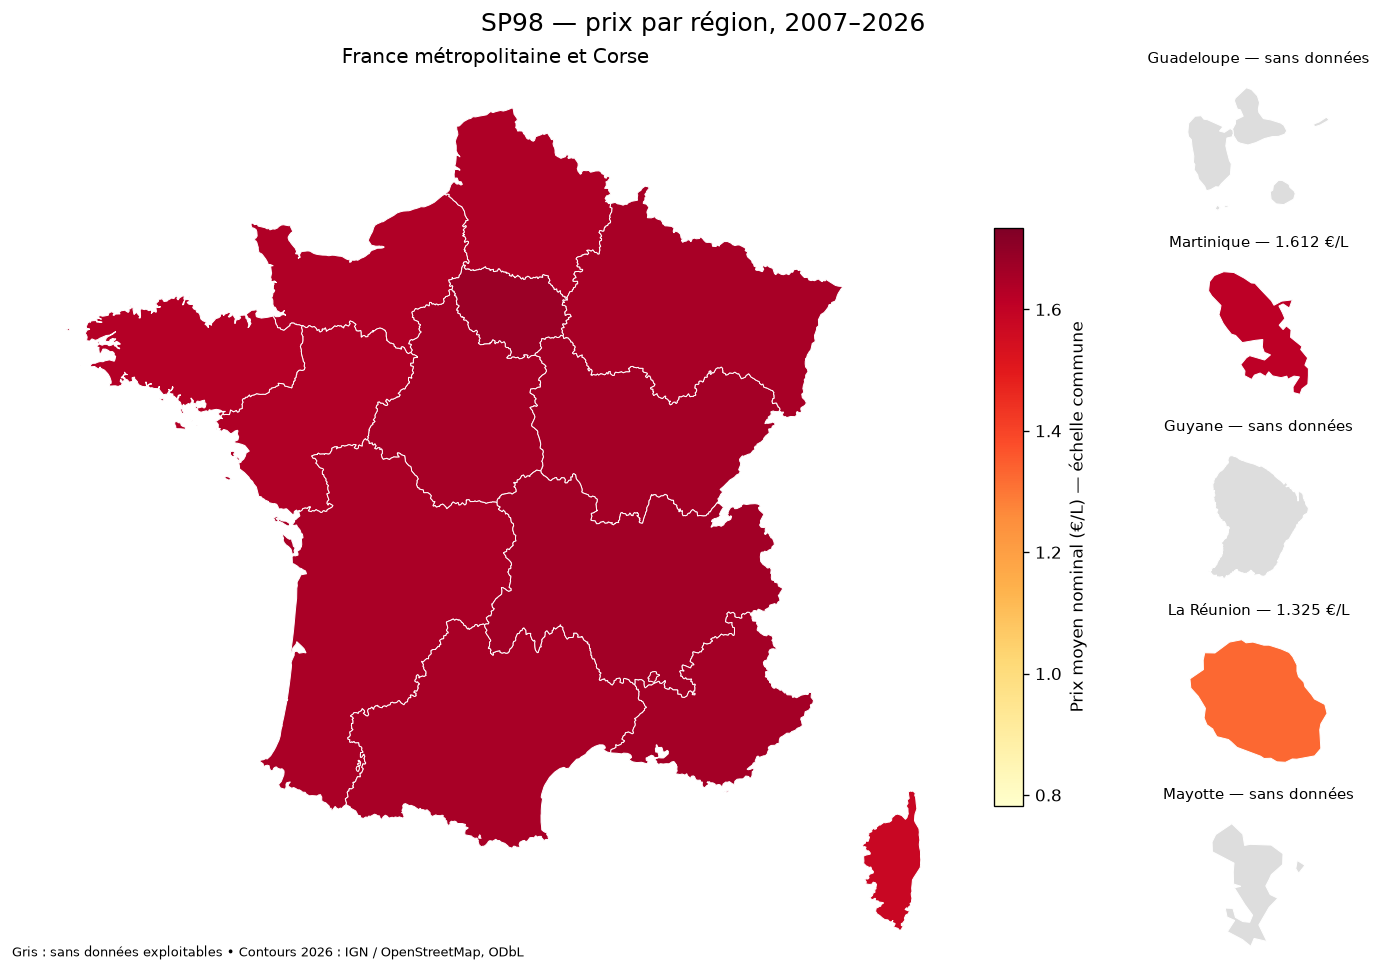

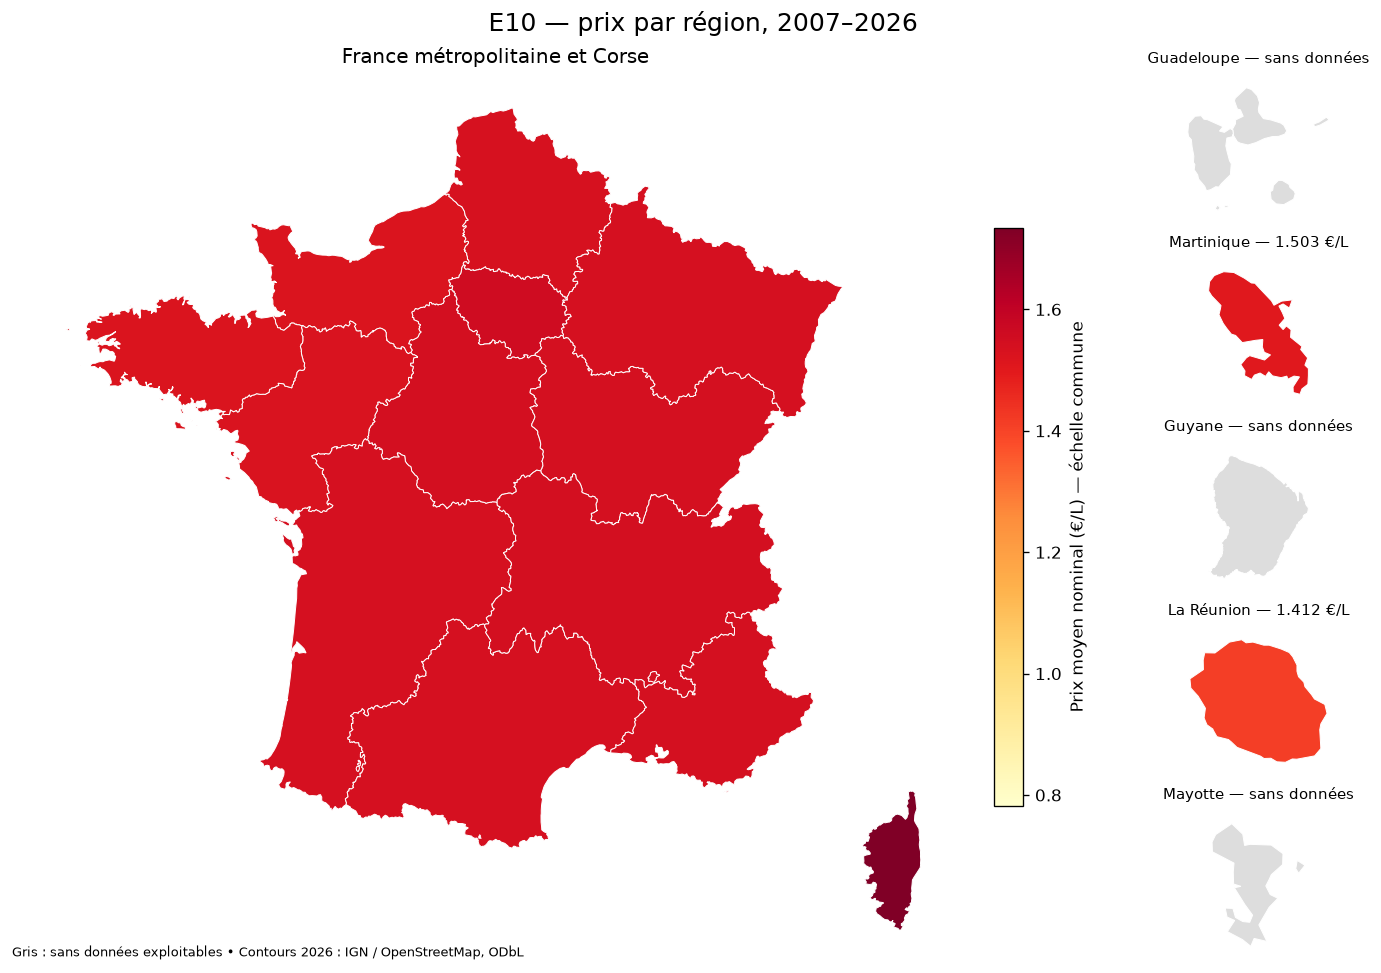

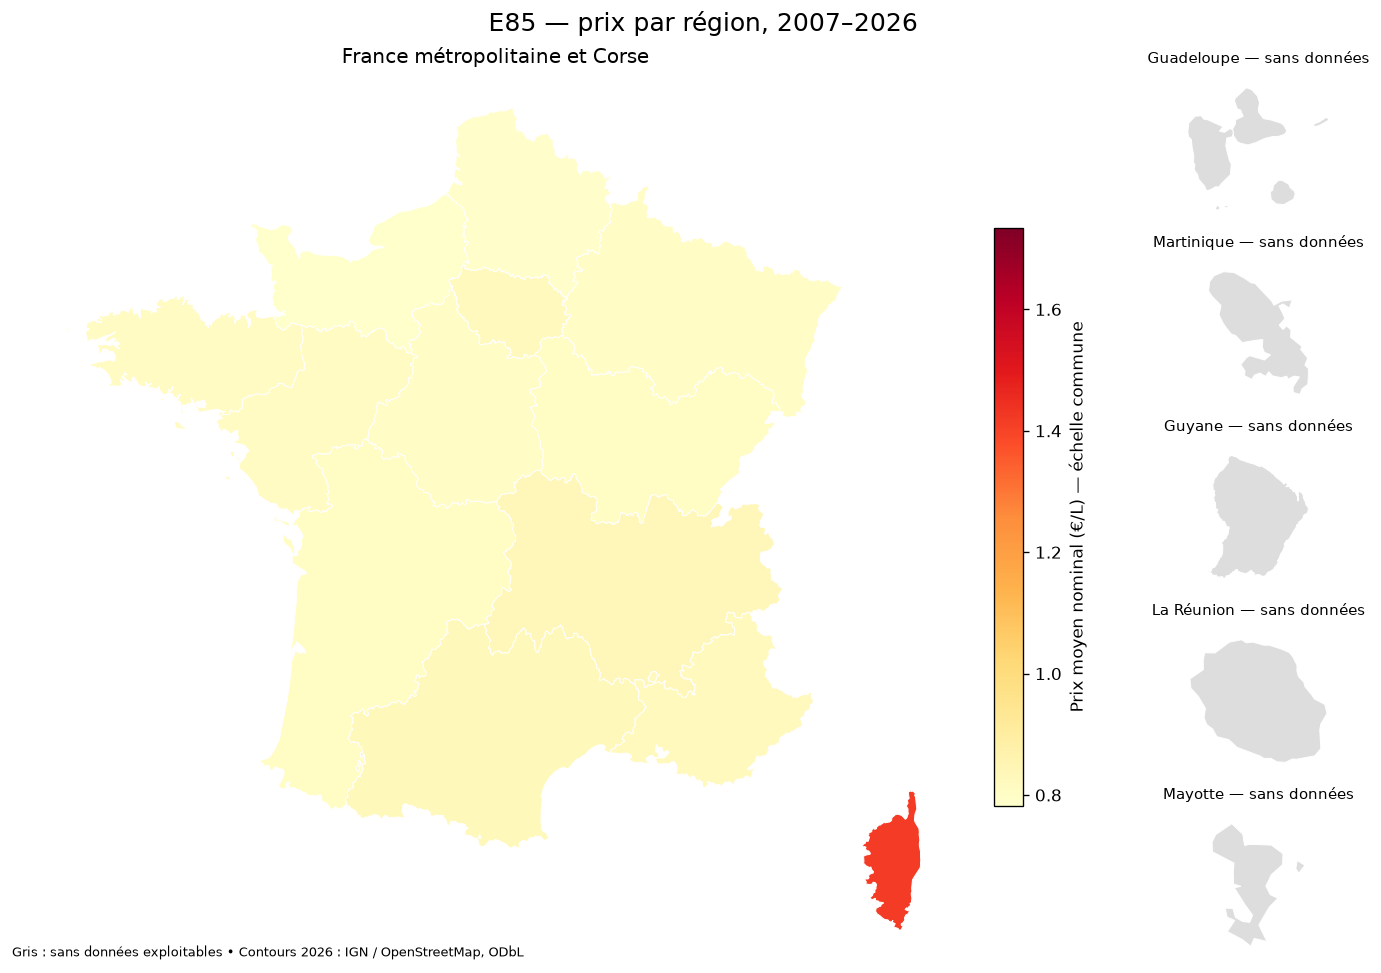

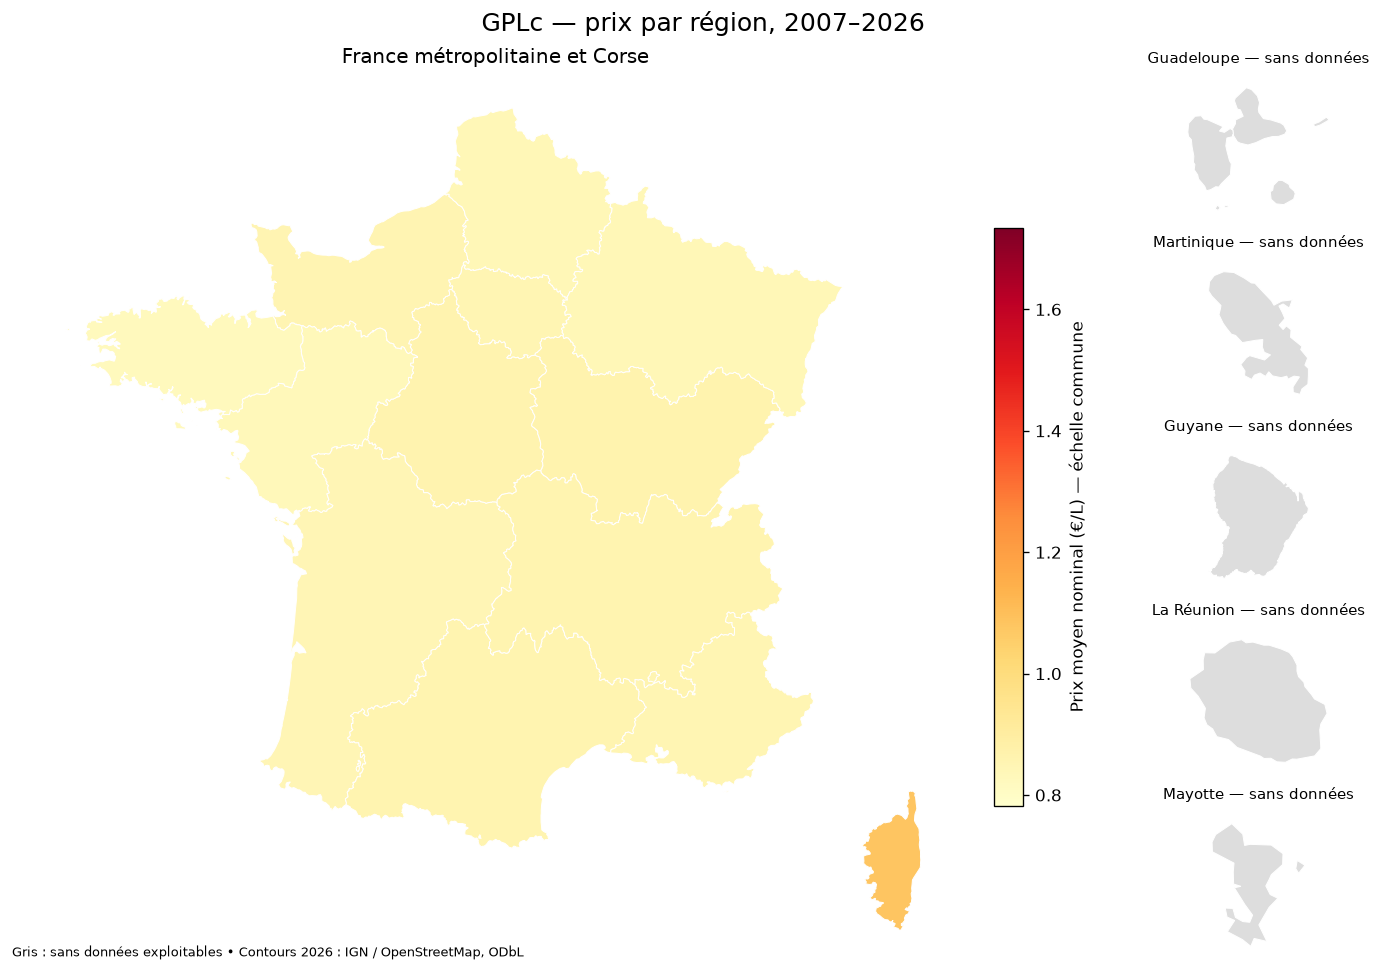

,region_name,fuel,price,days,stations_per_day,first_date,last_date
4,La Réunion,E10,1.411931,391,1.000000,2013-12-24,2017-12-29
0,Martinique,E10,1.503403,610,1.000000,2009-04-24,2014-12-18
49,Bretagne,E10,1.523954,6356,94.878697,2009-04-01,2026-11-11
25,Normandie,E10,1.524831,6319,99.293401,2009-04-02,2026-11-11
43,Pays de la Loire,E10,1.526328,6342,109.645222,2009-04-02,2026-11-11
...,...,...,...,...,...,...,...
18,Centre-Val de Loire,SP98,1.656333,4888,118.566080,2013-06-25,2026-11-11
24,Bourgogne-Franche-Comté,SP98,1.661502,4887,122.972990,2013-06-25,2026-11-11
78,Provence-Alpes-Côte d'Azur,SP98,1.662057,4888,229.464198,2013-06-25,2026-11-11
72,Auvergne-Rhône-Alpes,SP98,1.666424,4888,301.238953,2013-06-25,2026-11-11


In [ ]:
norm = Normalize(vmin=region_prices['price'].min(), vmax=region_prices['price'].max())
cmap = plt.get_cmap('YlOrRd')
overseas = ['01','02','03','04','06']
for fuel in COLORS:
    values = region_prices.loc[region_prices['fuel'].eq(fuel)].set_index('region')['price']
    fig = plt.figure(figsize=(12,8), layout='constrained')
    gs = fig.add_gridspec(5, 4)
    mainland_ax = fig.add_subplot(gs[:, :3])
    small_axes = {code:fig.add_subplot(gs[i,3]) for i,code in enumerate(overseas)}
    for feature in regions:
        code = feature['properties']['code']
        ax = small_axes.get(code, mainland_ax)
        price = values.get(code, np.nan)
        face = cmap(norm(price)) if pd.notna(price) else '#dddddd'
        for rings in polygons(feature):
            ax.add_patch(Polygon(rings[0], closed=True, facecolor=face, edgecolor='white', linewidth=.6))
            for hole in rings[1:]:
                ax.add_patch(Polygon(hole, closed=True, facecolor='white', edgecolor='white', linewidth=.3))
    mainland_ax.set_xlim(-5.5,10); mainland_ax.set_ylim(41,51.5)
    mainland_ax.set_aspect(1/np.cos(np.radians(46.5)))
    mainland_ax.set_title('France métropolitaine et Corse')
    for code, ax in small_axes.items():
        ax.autoscale_view(); ax.margins(.12)
        feature = next(f for f in regions if f['properties']['code'] == code)
        lat = np.mean([p[1] for rings in polygons(feature) for p in rings[0]])
        ax.set_aspect(1/np.cos(np.radians(lat)))
        price = values.get(code, np.nan)
        ax.set_title(region_names[code] + (f' — {price:.3f} €/L' if pd.notna(price) else ' — sans données'), fontsize=9)
    for ax in [mainland_ax, *small_axes.values()]: ax.axis('off')
    fig.colorbar(ScalarMappable(norm=norm,cmap=cmap), ax=mainland_ax, shrink=.65, label='Prix moyen nominal (€/L) — échelle commune')
    fig.suptitle(f'{fuel} — prix par région, {FILES[0].stem}–{FILES[-1].stem}', fontsize=15)
    fig.text(.02,.01,'Gris : sans données exploitables • Contours 2026 : IGN / OpenStreetMap, ODbL',fontsize=8)
    plt.show()
display(region_prices[['region_name','fuel','price','days','stations_per_day','first_date','last_date']].sort_values(['fuel','price']))